# Model A (Optimized): Advanced Environment-Only Review Prediction

This model uses **LDA (Linear Discriminant Analysis)** to compress logistical situations into separation-focused components, along with interaction terms and a tuned XGBoost regressor.

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# 1. Load and Feature Engineering
df = pd.read_csv('../../datasets/processed/olist_reviews_rich.csv')

# Interaction & Scaled features
df['log_price'] = np.log1p(df['price'])
df['log_distance'] = np.log1p(df['distance_km'])
df['freight_ratio'] = df['freight_value'] / (df['price'] + 1)
df['late_delay'] = df['is_late'] * df['delivery_delay_days']
df['price_x_delay'] = df['log_price'] * df['delivery_delay_days']

base_features = [
    'actual_delivery_days', 'delivery_delay_days', 'is_late', 'log_distance', 
    'log_price', 'freight_ratio', 'late_delay', 'price_x_delay', 
    'product_weight_g', 'product_photos_qty', 'n_items'
]

X = df[base_features].fillna(df[base_features].median())
y = df['review_score']
y_class = y.astype(int) # for LDA

# 2. Dimensionality Reduction (LDA)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
lda = LDA(n_components=4)
X_lda = lda.fit_transform(X_scaled, y_class)

# Add LDA components to X
for i in range(4):
    X[f'lda_{i}'] = X_lda[:, i]

# 3. Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Final Feature count: {X.shape[1]}")

Final Feature count: 15


## 1. Train Tuned XGBoost Model A

In [2]:
xgb_model_a = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.03,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method='hist',
    random_state=42,
    early_stopping_rounds=50
)

xgb_model_a.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=100)

y_pred = xgb_model_a.predict(X_test)

print(f"\nRMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"R2 Score: {r2_score(y_test, y_pred):.4f}")

[0]	validation_0-rmse:1.27809
[100]	validation_0-rmse:1.13811
[163]	validation_0-rmse:1.13817

RMSE: 1.1378
R2 Score: 0.2176


## 2. Feature Importance Check

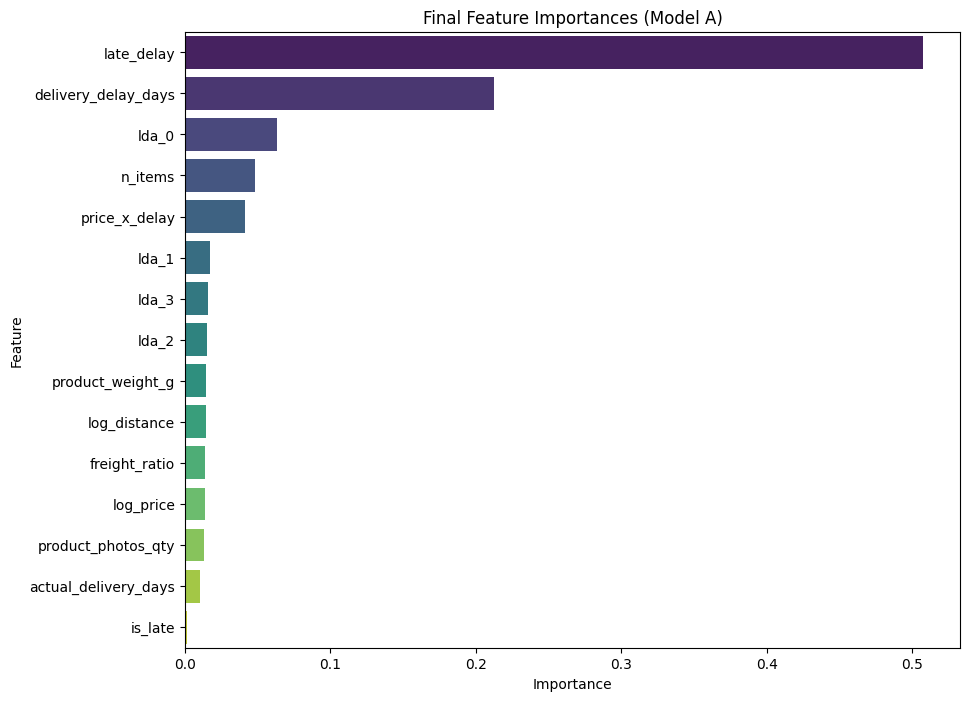

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

importances = xgb_model_a.feature_importances_
feat_names = X.columns.tolist()

# Create DataFrame for plotting
importance_df = pd.DataFrame({
    'Feature': feat_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature', data=importance_df, hue='Feature', palette='viridis', legend=False)
plt.title('Final Feature Importances (Model A)')
plt.show()

## 3. Save Predictions for Residual Analysis

In [4]:
# Save predictions back to the full dataframe
df['expected_review_A'] = xgb_model_a.predict(X)
df.to_csv('../../datasets/processed/olist_reviews_with_preds.csv', index=False)
print(f"Saved predictions to olist_reviews_with_preds.csv. Shape: {df.shape}")

Saved predictions to olist_reviews_with_preds.csv. Shape: (94009, 45)
